In [1]:
import sklearn.ensemble
import numpy as np
import pandas as pd
from IPython.display import HTML, display
import lime
import lime.lime_tabular
np.random.seed(1)

## Cechy liczbowe i kategoryczne w tym samym zbiorze danych

W tym notebooku będziemy analizować zbiór danych zawierający cechy liczbowe oraz kategoryczne. Nasze zadanie polega na predykcji czy dana osoba zarabia powyżej 50 000 dolarów rocznie.

In [2]:
feature_names = ["Age", "Workclass", "fnlwgt", "Education", "Education-Num", "Marital Status", "Occupation", "Relationship", "Race", "Sex", "Capital Gain", "Capital Loss","Hours per week", "Country"]

In [3]:
data = np.genfromtxt('https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data', delimiter=', ', dtype=str)

Przyjrzyjmy się zbiorowi danych. Przeanalizujmy etykiety:

In [4]:
labels = data[:, 14]
np.unique(labels)

array(['<=50K', '>50K'], dtype='<U26')

Aby skutecznie używać etykiet, nadajmy im dyskretne wartości liczbowe:

In [5]:
le= sklearn.preprocessing.LabelEncoder()
le.fit(labels)
labels = le.transform(labels)
class_names = le.classes_

In [6]:
np.unique(labels)

array([0, 1])

Usuńmy etykiety z macierzy danych i spójrzmy, co zawiera zbiór:

In [7]:
data = data[:, :-1]

In [8]:
pd.DataFrame(data, columns=feature_names)

,Age,Workclass,fnlwgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States


Zbiór danych zawiera wiele cech kategorycznych, które musimy potraktować tak samo, jak wcześniej etykiety - LIME (oraz większość klasyfikatorów) operuje na danych liczbowych, nawet, jeśli poszczególne cechy są de facto kategoryczne. Z tego powodu wykorzystamy LabelEncoder z biblioteki sklearn, aby przetransformować wszystkie łancuchy znaków w liczby. Wykorzystamy słownik (dict), aby zapisać mapowanie między liczbami oraz oryginalnymi wartościami cech, z których skorzystamy później przy prezentacji wyjaśnień.

In [9]:
categorical_features = [1, 3, 5, 6, 7, 8, 9, 13]

In [10]:
categorical_names = {}
for feature in categorical_features:
    le = sklearn.preprocessing.LabelEncoder()
    le.fit(data[:, feature])
    data[:, feature] = le.transform(data[:, feature])
    categorical_names[feature] = le.classes_

In [11]:
le.classes_

array(['?', 'Cambodia', 'Canada', 'China', 'Columbia', 'Cuba',
       'Dominican-Republic', 'Ecuador', 'El-Salvador', 'England',
       'France', 'Germany', 'Greece', 'Guatemala', 'Haiti',
       'Holand-Netherlands', 'Honduras', 'Hong', 'Hungary', 'India',
       'Iran', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Laos', 'Mexico',
       'Nicaragua', 'Outlying-US(Guam-USVI-etc)', 'Peru', 'Philippines',
       'Poland', 'Portugal', 'Puerto-Rico', 'Scotland', 'South', 'Taiwan',
       'Thailand', 'Trinadad&Tobago', 'United-States', 'Vietnam',
       'Yugoslavia'], dtype='<U26')

In [12]:
data = data.astype(float)

Zobaczmy, jak ostatecznie prezentują się nasze dane:

In [13]:
pd.DataFrame(data, columns=feature_names)

,Age,Workclass,fnlwgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7.0,77516.0,9.0,13.0,4.0,1.0,1.0,4.0,1.0,2174.0,0.0,40.0,39.0
1,50.0,6.0,83311.0,9.0,13.0,2.0,4.0,0.0,4.0,1.0,0.0,0.0,13.0,39.0
2,38.0,4.0,215646.0,11.0,9.0,0.0,6.0,1.0,4.0,1.0,0.0,0.0,40.0,39.0
3,53.0,4.0,234721.0,1.0,7.0,2.0,6.0,0.0,2.0,1.0,0.0,0.0,40.0,39.0
4,28.0,4.0,338409.0,9.0,13.0,2.0,10.0,5.0,2.0,0.0,0.0,0.0,40.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,4.0,257302.0,7.0,12.0,2.0,13.0,5.0,4.0,0.0,0.0,0.0,38.0,39.0
32557,40.0,4.0,154374.0,11.0,9.0,2.0,7.0,0.0,4.0,1.0,0.0,0.0,40.0,39.0
32558,58.0,4.0,151910.0,11.0,9.0,6.0,1.0,4.0,4.0,0.0,0.0,0.0,40.0,39.0
32559,22.0,4.0,201490.0,11.0,9.0,4.0,1.0,3.0,4.0,1.0,0.0,0.0,20.0,39.0


In [14]:
pd.DataFrame(data, columns=feature_names).describe()

,Age,Workclass,fnlwgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
count,32561.000000,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,3.868892,1.897784e+05,10.298210,10.080679,2.611836,6.572740,1.446362,3.665858,0.669205,1077.648844,87.303830,40.437456,36.718866
std,13.640433,1.455960,1.055500e+05,3.870264,2.572720,1.506222,4.228857,1.606771,0.848806,0.470506,7385.292085,402.960219,12.347429,7.823782
min,17.000000,0.000000,1.228500e+04,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,4.000000,1.178270e+05,9.000000,9.000000,2.000000,3.000000,0.000000,4.000000,0.000000,0.000000,0.000000,40.000000,39.000000
50%,37.000000,4.000000,1.783560e+05,11.000000,10.000000,2.000000,7.000000,1.000000,4.000000,1.000000,0.000000,0.000000,40.000000,39.000000
75%,48.000000,4.000000,2.370510e+05,12.000000,12.000000,4.000000,10.000000,3.000000,4.000000,1.000000,0.000000,0.000000,45.000000,39.000000
max,90.000000,8.000000,1.484705e+06,15.000000,16.000000,6.000000,14.000000,5.000000,4.000000,1.000000,99999.000000,4356.000000,99.000000,41.000000


Wartości zmiennych kategorycznych zostały zamienione na liczby, które mapują się do poszczególnych kategorii.
Podzielimy teraz dane na części treningową i testową:

In [15]:
train, test, labels_train, labels_test = sklearn.model_selection.train_test_split(data, labels, train_size=0.80)

Aby klasyfikator nie traktował zmiennych kategorycznych jako ciągłych wartości, wykorzystamy One-hot encoder do ostatecznego przekształcenia cech. Wykorzystamy ten enkoder wyłącznie dla klasyfikatora, a nie dla modelu wewnątrz LIME - biblioteka lime sama zadba o przekształcenie one-hot cech kategorycznych.

*Nie chcemy podawać do modelu z LIME cech przekształconych one-hot, ponieważ utrudnimy w ten sposób generowanie przykładów podobnych do analizowanego w jego "okolicy" - może się zdarzyć, że nowy przykład będzie miał ustawionych kilka wartości cechy one-hot na "1", co nie ma sensu.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [17]:
encoder = ColumnTransformer([("OneHot", OneHotEncoder(), categorical_features)], remainder = 'passthrough')

In [18]:
encoder.fit(data)
encoded_train = encoder.transform(train)

Jako klasyfikator wykorzystamy model "gradient boosted trees" z pakietu xgboost:

In [19]:
import xgboost
gbtree = xgboost.XGBClassifier(n_estimators=300, max_depth=5)
gbtree.fit(encoded_train, labels_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [20]:
sklearn.metrics.accuracy_score(labels_test, gbtree.predict(encoder.transform(test)))

0.8685705512052817

Przygotujmy funkcję do predykcji, która najpierw przekształca dane do reprezentacji one-hot (przyda nam się ona później):

In [21]:
predict_fn = lambda x: gbtree.predict_proba(encoder.transform(x)).astype(float)

### Wyjaśnianie predykcji

"Wyjaśniacze" dla danych tabelarycznych wykorzystują zbiór danych treningowych do wyliczania statystyk dla każdej cechy (kolumny). Dla danych ciągłych wyliczane są średnia i odchylenie standardowe, a także dokonywana jest ich dyskretyzacja z wykorzystaniem kwartyli. Dla danych kategorycznych wyliczane są częstości wystąpienia każdej wartości.

Te statystyki wykorzystywane są na dwa sposoby:
* Do skalowania danych, aby móc skutecznie wyliczać odległości między próbkami, gdy cechy mają różne zakresy wartości;
* Do przygotowywania próbek "naokoło" analizowanej
    * dla danych liczbowych losujemy wartość z rozkładu Normalnego (N(0,1)), mnożymy ją przez odchylenie standardowe i dodajemy średnią wyliczoną dla danej cechy
    * dla danych kategorycznych losujemy nową wartość cechy zgodnie z rozkładem wartości w danych treningowych, a następnie ustawiamy wartość związanej z nią nowej binarnej cechy na "1", jeśli jest taka sama jak dla analizowanego przykładu, a w przeciwnym razie na "0" (analizowanemu przykładowi ustawiamy wartość nowej binarnej cechy na "1").

Przygotujmy teraz "explainer". Przez parametr categorical_features przekazujemy informację o tym, które zmienne są kategoryczne. Dzięki parametrowi categorical_names model zna mapowanie miedzy numerycznymi wartościami cech oraz oryginalnymi wartościami cech.

In [22]:
feature_names

['Age',
 'Workclass',
 'fnlwgt',
 'Education',
 'Education-Num',
 'Marital Status',
 'Occupation',
 'Relationship',
 'Race',
 'Sex',
 'Capital Gain',
 'Capital Loss',
 'Hours per week',
 'Country']

In [23]:
explainer = lime.lime_tabular.LimeTabularExplainer(train, feature_names=feature_names, class_names=class_names,
                                                   categorical_features=categorical_features,
                                                   categorical_names=categorical_names, kernel_width=3, verbose=True)

Przeanalizujmy teraz kilka wyjaśnień przy fladze verbose ustawionej na True, dzięki czemu poznamy predykcje lokalnego modelu wewnątrz LIME.

In [24]:
i = 1653
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept -0.010839063271282673
Prediction_local [1.05468397]
Right: 0.9999929666519165


In [25]:
exp.as_list()

[('Capital Gain > 0.00', 0.7007898837859567),
 ('Marital Status=Married-civ-spouse', 0.12376752143438044),
 ('Education-Num > 12.00', 0.09497993013967185),
 ('Hours per week > 45.00', 0.08136965392241272),
 ('Age > 48.00', 0.06461604685975442)]

Przeanalizujmy wyniki:

Po pierwsze, zauważmy, że wyjaśniany przykład wyświetlony jest z prawej strony w formie tabeli. Ponieważ ustawiliśmy wartość parametru show_all na wartość False, wyświetlane są wyłącznie cechy wykorzystane w wyjaśnieniach.

Kolumna "value" wyświetla wartości dla każdej z cech.

Wyjaśnienia dla cech kategorycznych bazują nie tylko na cechach, ale na parach cecha-wartość.

LIME przeprowadził dyskretyzację cech w wyjaśnieniach. Stało się tak, ponieważ ustawiliśmy discretize_continuous na True w konstruktorze (domyślna opcja). Takie wartości pomagają w uzyskaniu bardziej intuicyjnych wyjaśnień.

Przeanalizujmy krótko wartości wyświetlone po ustawieniu verbose na True: Intercept to wyraz wolny modelu liniowego użytego w środku algorytmu LIME. Prediction_local to predykcja tego modelu dla wyjaśnianego przykładu, zaś Right - predykcja modelu xgboost dla tego samego przykładu. Wagi dla każdej z cech analizujemy uwzględniając wyraz wolny.

Zauważmy, że cecha "Capital gain" ma bardzo wysoką wagę, co brzmi sensownie. Przeanalizujmy teraz przykład, w którym predykcja jest inna:

In [26]:
i = 92
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept 0.8242496187724715
Prediction_local [0.10456458]
Right: 0.08679622411727905


Przeanalizujmy też jeden "dziwny" przykład. Przyjrzyj się wyjaśnieniom:

In [27]:
i = 18
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept 0.12865598616631146
Prediction_local [0.80961204]
Right: 0.0069765751250088215


Model xgboost przewidział wynik "<=50K", a wyjaśnienia sugerują odwrotny rezultat. Przeprowadźmy analizę:
intercept + wagi = prediction_local, czyli predykcja modelu wewnątrz LIME, związana z etykietą ">50K". Predykcja xgboosta jest bliska 0, więc w tym przypadku LIME nie wyjaśnia nam skutecznie predykcji xgboosta.

## Zadanie domowe

Część I - LIME:
* Wybierz inny, wskazany przez prowadzącego model do predykcji zamiast xgboost.
* Przygotuj explainer dla wybranego modelu.
* Wykorzystaj go na trzech przykładach użytych w tutorialu. Czy predykcje oraz wyjaśnienia uległy zmianie? Przeanalizuj, czy wyjaśnienia są sensowne (czy wpływ poszczególnych cech na wynik jest intuicyjnie poprawny).
* Wyjaśnij przykład, w którym predykcja **wybranego modelu** jest niepoprawna. W tym celu porównaj etykiety ze zbioru testowego z etykietami po predykcji i wybierz przykład, dla którego mają one inne wartości. Wyjaśnij go z pomocą LIME (zwróć uwagę, żeby predykcja modelu wewnątrz LIME pokrywała się z predykcją wybranego modelu). Skomentuj wyniki - jakie wartości cech zmyliły model?
* Znajdź i wyjaśnij jeden dodatkowy interesujący przykład.

In [28]:
rf = sklearn.ensemble.RandomForestClassifier(n_estimators=300, random_state=1)
rf.fit(encoded_train, labels_train)
predict_fn = lambda x: rf.predict_proba(encoder.transform(x)).astype(float)

In [29]:
i = 1653
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept 0.05829026830470779
Prediction_local [0.88738629]
Right: 0.9933333333333333


In [30]:
i = 92
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept 0.6573876437805484
Prediction_local [0.23395745]
Right: 0.5566666666666666


In [31]:
i = 18
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept 0.18490278108522504
Prediction_local [0.69200492]
Right: 0.09666666666666666


In [32]:
# Błędnie sklasyfikowany przykład
i = 66
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept 0.6101771910957362
Prediction_local [0.2959231]
Right: 0.4533333333333333


In [33]:
probs = predict_fn(test)[:, 1]

idx = np.where((test[:, 0] > 40) & (test[:, 12] >= 50) & (labels_test == 0))[0]

df = pd.DataFrame(test[idx], columns=feature_names)
df.insert(0, "i", idx)
df["P(>50K)"] = probs[idx].round(2)
df.sort_values("Hours per week", ascending=False)

,i,Age,Workclass,fnlwgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country,P(>50K)
31,639,62.0,4.0,272209.0,11.0,9.0,0.0,9.0,4.0,2.0,0.0,0.0,0.0,99.0,39.0,0.12
227,5204,55.0,6.0,185195.0,9.0,13.0,2.0,4.0,0.0,4.0,1.0,0.0,0.0,99.0,39.0,0.64
239,5477,44.0,6.0,277783.0,12.0,14.0,4.0,5.0,3.0,4.0,1.0,0.0,0.0,99.0,39.0,0.18
68,1349,53.0,6.0,162576.0,5.0,4.0,2.0,13.0,0.0,4.0,1.0,0.0,0.0,99.0,39.0,0.33
273,6053,48.0,6.0,185385.0,11.0,9.0,2.0,5.0,0.0,4.0,1.0,0.0,0.0,98.0,39.0,0.29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
287,6340,54.0,6.0,42924.0,15.0,10.0,2.0,12.0,0.0,4.0,1.0,0.0,0.0,50.0,39.0,0.16
286,6337,64.0,4.0,75577.0,5.0,4.0,2.0,1.0,0.0,4.0,1.0,2580.0,0.0,50.0,39.0,0.15
9,212,58.0,5.0,100960.0,11.0,9.0,2.0,12.0,0.0,4.0,1.0,0.0,0.0,50.0,39.0,0.76
8,196,42.0,4.0,85995.0,11.0,9.0,2.0,14.0,0.0,4.0,1.0,0.0,0.0,50.0,39.0,0.42


In [34]:
# Człowiek który ma zerowe zyski kapitałowe i spore straty, do tego pracuje 18h w tygodniu a mimo to zarabia >50k. Model poprawnie go sklasyfikował, ale lime nie.
i = 4941
exp = explainer.explain_instance(test[i], predict_fn, num_features=5)
display(HTML(exp.as_html()))

Intercept 0.6148639186267494
Prediction_local [0.3036203]
Right: 0.79


- Dla każdego przykładu najważniejsze cechy są takie same i wskazują na tą samą klasę. Jedyną różnicę widać na piątej cesze. Intuicyjnie wyróżnione cechy mają sens. 
- W błędnym przykładzie model został zmylony przez *Capital Gain*, czyli konsekwentnie najważniejszą cechę. Reprezentuje ona zyski kapitałowe, jest to natomiast możliwe że ktoś dużo zarabia a mimo to nie inwestuje na giełdzie
- W większości ciekawych przykładów model i explainer nię ze sobą nie zgadzają.

Część II - SHAP:
* Przygotuj explainer SHAP dla modelu z Części I. Skorzystaj z biblioteki shap. Dopilnuj, żeby cechy w wyjaśnieniach były odpowiednio nazwane, tzn. aby nie występowały nazwy typu "Feature x" - możesz skorzystać z kodu podanego poniżej.
* Wyjaśnij model - skorzystaj z wykresów barplot oraz beeswarm. Które cechy najbardziej wpływają na wynik, jakie są kierunki zależności? Czy mają intuicyjny sens? Skomentuj wyniki.
* Wyjaśnij pięć przykładów (3 z zajęć + 2 z zadania LIME) z pomocą SHAP. Skorzystaj z wykresów waterfall. Skomentuj wyniki.
* Porównaj wyjaśnienia SHAP oraz LIME. Która metoda radzi sobie intuicyjnie lepiej, która bardziej Ci się podoba?

In [35]:
import shap
import scipy.sparse as sp
import matplotlib.pyplot as plt

c:\Users\Lukasz\Documents\GitHub\machine-learning-s9\lab03\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [36]:
all_features_list = []

for i in range(len(feature_names)):
    if i in categorical_features:
        all_features_list.extend([feature_names[i] + "=" + n for n in categorical_names[i]])

for i in range(len(feature_names)):
    if i not in categorical_features:
        all_features_list.append(feature_names[i])

In [37]:
model = rf

X_test_enc = encoder.transform(test)
if sp.issparse(X_test_enc):
    X_test_enc = X_test_enc.toarray()

assert len(all_features_list) == X_test_enc.shape[1]
X_test_df = pd.DataFrame(X_test_enc, columns=all_features_list)

In [44]:
explainer_shap = shap.TreeExplainer(model)

rng = np.random.default_rng(1)
sample_idx = rng.choice(len(test), size=200, replace=False)

sv_all = explainer_shap(X_test_df.iloc[sample_idx], check_additivity=False)
sv = sv_all[:, :, 1] if len(sv_all.shape) == 3 else sv_all

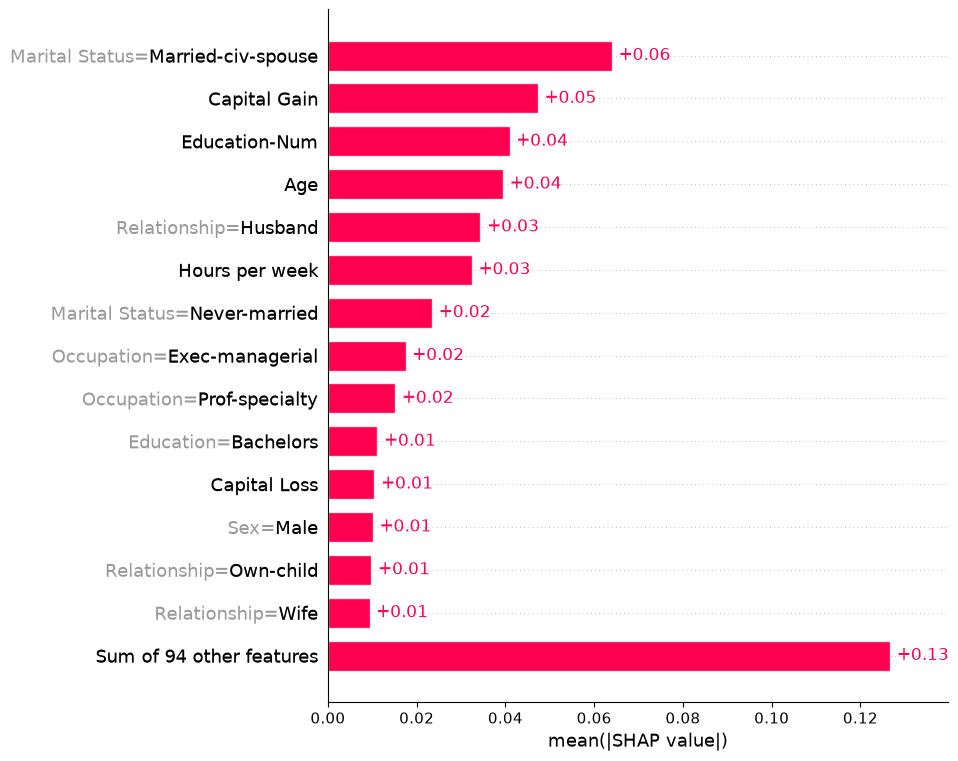

In [45]:
shap.plots.bar(sv, max_display=15)

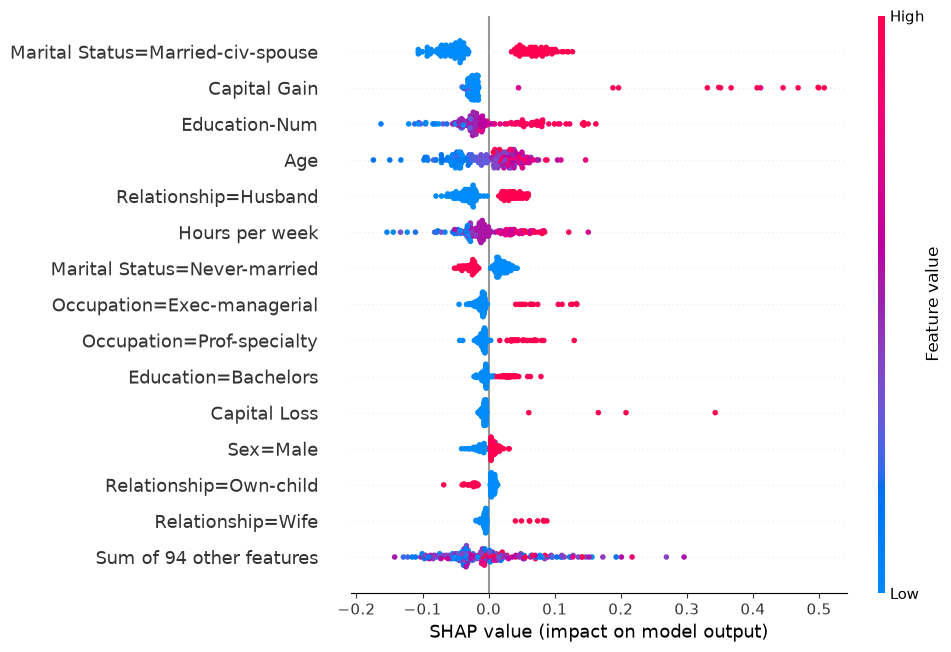

In [46]:
shap.plots.beeswarm(sv, max_display=15)

In [47]:
orig_feature = [n.split("=")[0] for n in all_features_list]
abs_sum = (pd.DataFrame(np.abs(sv.values), columns=all_features_list)
             .T.groupby(orig_feature).sum().T)
abs_sum.mean().sort_values(ascending=False)

Marital Status    0.092696
Relationship      0.067687
Occupation        0.064724
Capital Gain      0.047313
Education-Num     0.040922
Education         0.039651
Age               0.039469
Hours per week    0.032442
Sex               0.018117
Workclass         0.017596
Capital Loss      0.010484
fnlwgt            0.009288
Country           0.006858
Race              0.005097
dtype: float64

In [50]:
i_wrong = 66
i_interesting = 4941

examples = {"tutorial 1653": 1653, "tutorial 92": 92, "tutorial 18": 18,
            "misclassified": i_wrong, "interesting": i_interesting}

sv_ex_all = explainer_shap(X_test_df.iloc[list(examples.values())], check_additivity=False)
sv_ex = sv_ex_all[:, :, 1] if len(sv_ex_all.shape) == 3 else sv_ex_all

=== tutorial 1653 (i=1653) | true: >50K | P(>50K)=0.99 | base=0.24 | base+sum=0.99


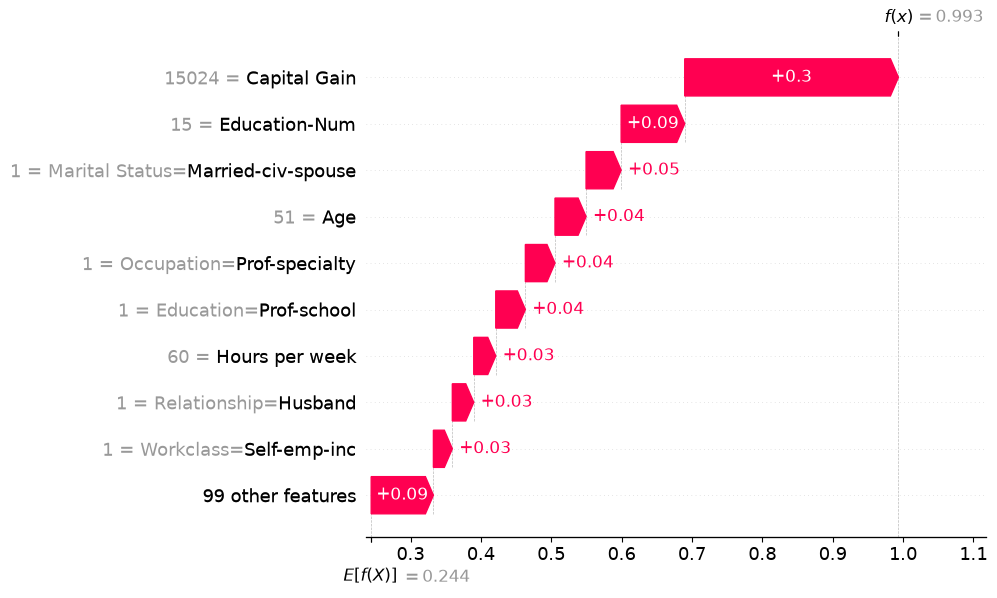

=== tutorial 92 (i=92) | true: <=50K | P(>50K)=0.56 | base=0.24 | base+sum=0.56


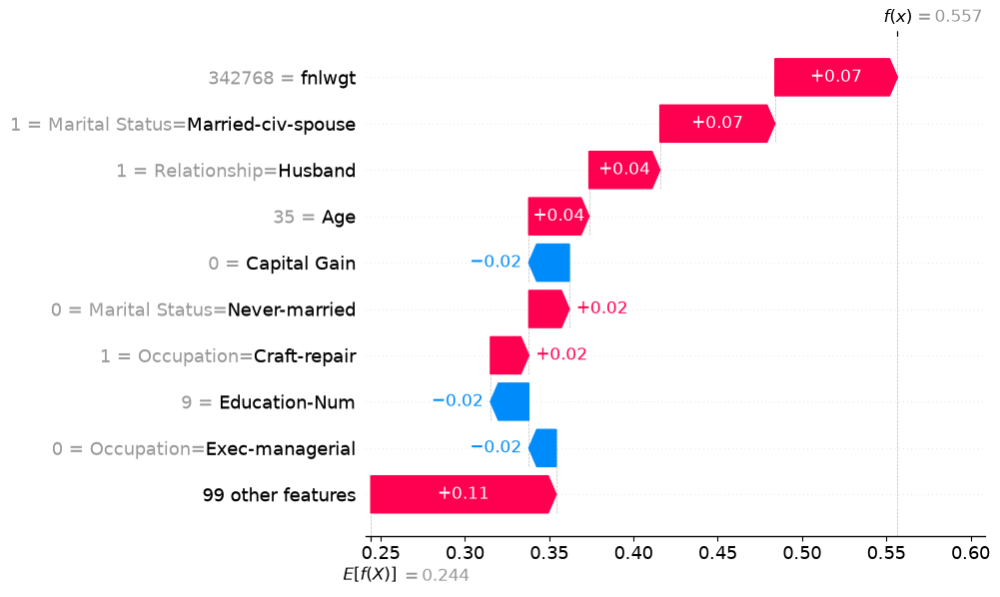

=== tutorial 18 (i=18) | true: <=50K | P(>50K)=0.10 | base=0.24 | base+sum=0.10


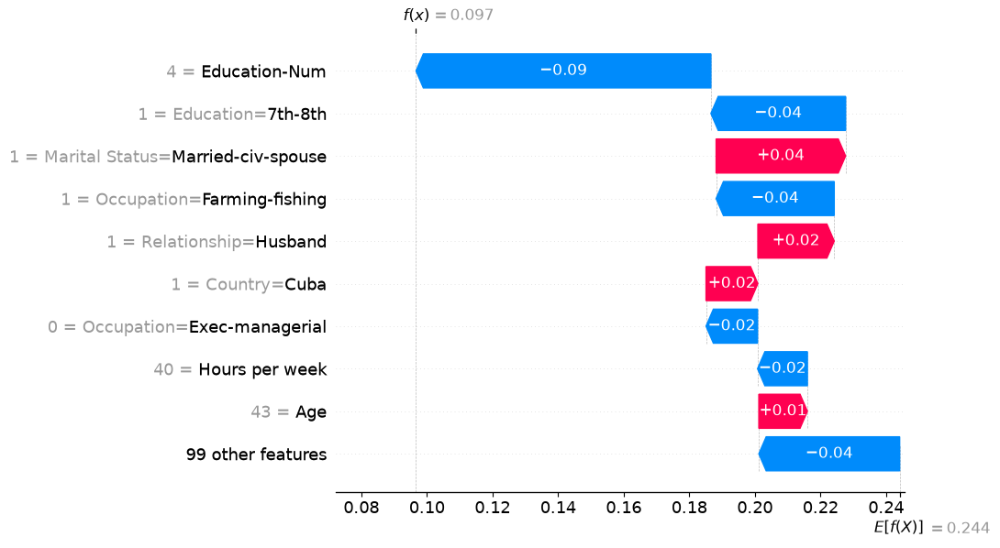

=== misclassified (i=66) | true: >50K | P(>50K)=0.45 | base=0.24 | base+sum=0.45


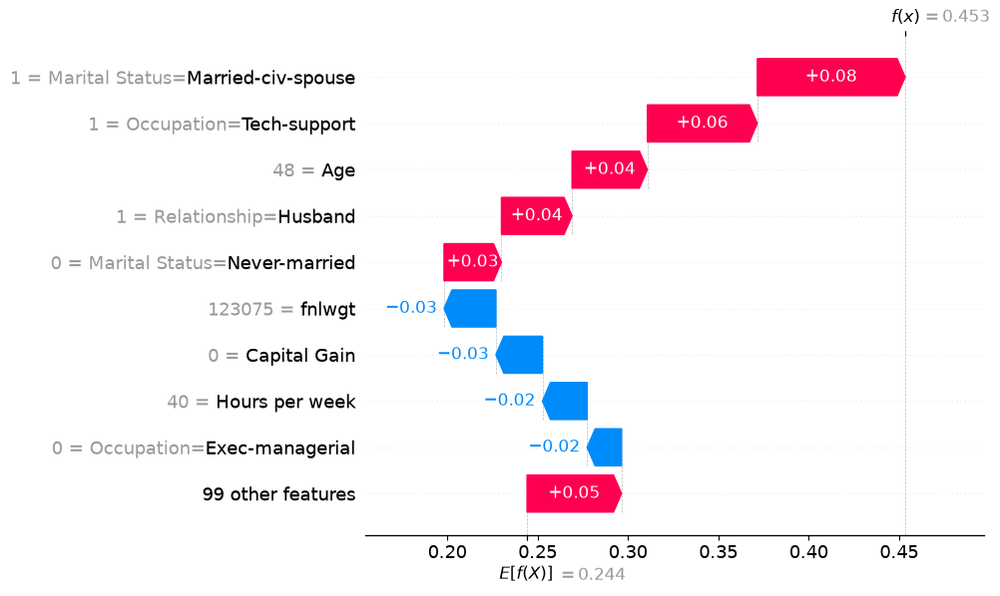

=== interesting (i=4941) | true: >50K | P(>50K)=0.79 | base=0.24 | base+sum=0.79


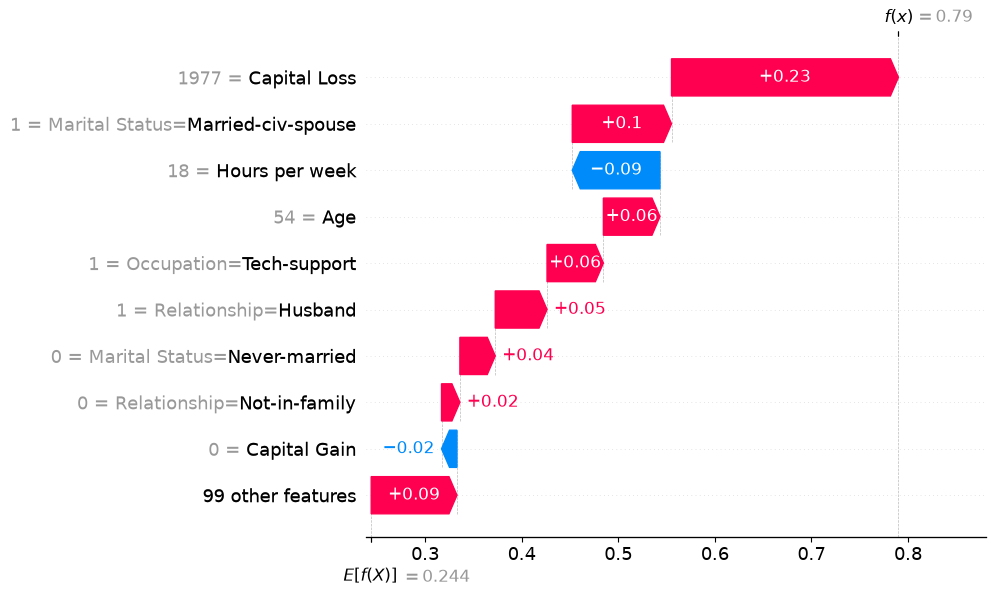

In [51]:
for k, (name, i) in enumerate(examples.items()):
    p = predict_fn(test[i:i+1])[0, 1]
    print(f"=== {name} (i={i}) | true: {class_names[labels_test[i]]} | "
          f"P(>50K)={p:.2f} | base={sv_ex[k].base_values:.2f} | "
          f"base+sum={sv_ex[k].base_values + sv_ex[k].values.sum():.2f}")
    shap.plots.waterfall(sv_ex[k], max_display=10, show=False)
    plt.show()

Wyjaśnienie globalne (barplot, beeswarm)

- Najważniejsze cechy: Marital Status=Married-civ-spouse, Capital Gain, Education-Num, Age, Relationship=Husband, Hours per week. Po zsumowaniu kolumn one-hot: Marital Status, Relationship, Occupation, Capital Gain, Education.
- Bycie w małżeństwie (Married-civ-spouse, Husband, Wife) zwiększa P(>50K), Never-married i Own-child je zmniejszają.
- Wyższe Education-Num, wiek i liczba godzin pracy zwiększają P(>50K), niskie wartości wyraźnie je obniżają.
- Capital Gain dla większości osób wynosi 0 i daje mały ujemny wpływ, ale gdy jest dodatni, daje bardzo duży skok w stronę >50K (do +0.5). Podobnie, choć słabiej, działa Capital Loss: kto ma straty, ten inwestuje.
- Zawody Exec-managerial i Prof-specialty oraz Sex=Male przesuwają w stronę >50K.
- Race, Country i fnlwgt mają marginalny wpływ.
- Zależności są intuicyjne. Małżeństwo prawdopodobnie działa pośrednio, bo koreluje z wiekiem, stabilną pracą i dochodem gospodarstwa.

Wyjaśnienia lokalne (waterfall, baza E[f(x)] = 0.24)

- 1653 (prawda >50K, P = 0.99): dominuje Capital Gain = 15024 (+0.30), potem wysoka edukacja (15 lat, Prof-school), małżeństwo i wiek 51. Wyjaśnienie sensowne.
- 92 (prawda <=50K, P = 0.56, błąd modelu): w górę ciągną małżeństwo, Husband i wiek 35, ale największy pojedynczy wkład ma fnlwgt (+0.07). fnlwgt to waga próbkowania spisu, a nie cecha osoby, więc las losowy częściowo się na niej przeuczył i to ona przesunęła wynik ponad 0.5.
- 18 (prawda <=50K, P = 0.10): niska edukacja (4 lata, 7th-8th) i zawód Farming-fishing ciągną w dół, czego małżeństwo nie równoważy. Sensowne.
- 66 (prawda >50K, P = 0.45, błąd modelu): w górę ciągną małżeństwo (+0.08), zawód Tech-support (+0.06), wiek 48 i Husband. W dół ciągną brak Capital Gain, standardowe 40 godzin pracy, zawód inny niż Exec-managerial i fnlwgt. Osoba ma profil typowy dla >50K, ale bez wyróżniających cech (zysków kapitałowych, nadgodzin), więc model zatrzymał się tuż pod progiem 0.5. Model zmyliło głównie to, że Capital Gain = 0, a dla modelu jest to jedna z najważniejszych cech.
- 4941 (prawda >50K, P = 0.79): największy wkład ma Capital Loss = 1977 (+0.23), potem małżeństwo, wiek 54 i Tech-support. Tylko 18 godzin pracy obniża wynik (-0.09), ale za słabo, żeby zmienić decyzję. Model trafił, a SHAP dobrze pokazuje dlaczego.

Porównanie SHAP i LIME

- SHAP jest dokładny: baza + suma wkładów = predykcja modelu, co widać w każdym przykładzie.
- LIME w przykładach 92, 18, 66 i 4941 dawał Prediction_local daleko od predykcji modelu, w 18 i 4941 nawet po przeciwnej stronie progu 0.5, więc jego wyjaśnienia były tam niewiarygodne.
- Dla przykładu 66 obie metody wskazują Capital Gain = 0 jako główny powód błędu, ale SHAP pokazuje też dokładnie, ile brakło do progu.
- TreeSHAP jest deterministyczny, LIME losuje sąsiadów i daje trochę inne wagi przy każdym uruchomieniu.
- SHAP daje też obraz globalny (barplot, beeswarm), LIME tylko lokalny.
- LIME jest czytelniejszy (warunki typu Capital Gain > 0, przedziały wieku), SHAP rozbija cechy kategoryczne na wiele kolumn one-hot.
- SHAP dla głębokiego lasu losowego liczy się bardzo długo, LIME szybko.
- Wniosek: SHAP radzi sobie lepiej i bardziej mi się podoba, bo jego wyjaśnienia zawsze są zgodne z modelem i mają intuicyjne kierunki. LIME jest szybki i czytelny, ale dla tego modelu często się rozjeżdżał.